In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Python executable: C:\Users\roban\ml-zoomcamp-2026-midterm\.venv\Scripts\python.exe


In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   --------------------- ------------------ 5.8/10.7 MB 32.0 MB/s eta 0:00:01
   --------


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Locate the cleaned 4G/5G dataset
data_files = list(Path("data").rglob("processed_data_cleaned.v2.csv"))

assert len(data_files) == 1, f"Expected one dataset, found {len(data_files)}"

# Load the dataset
df = pd.read_csv(data_files[0])

print("Dataset shape:", df.shape)
print("\nFirst 5 records:")
display(df.head())

Dataset shape: (30925, 51)

First 5 records:


,Timestamp,Longitude,Latitude,Speed,Operatorname,Node,CellID,LAC,NetworkTech,Level,...,TESTDOWNLINK,TESTUPLINK,TESTDOWNLINKMAX,TESTUPLINKMAX,Test_Status,Mobility,Node_Longitude,Node_Latitude,SessionID,ElapsedTime
0,2024.12.03_11.30.19,101.604079,3.067269,0.0,Operator C,702072.0,20.0,5123.0,5G,-98.0,...,NaN,NaN,NaN,NaN,NONE,Walk,101.601629,3.065296,1,0.0
1,2024.12.03_11.30.20,101.604065,3.067274,2.0,Operator C,702072.0,20.0,5123.0,5G,-101.0,...,NaN,NaN,NaN,NaN,NONE,Walk,101.601629,3.065296,1,1.0
2,2024.12.03_11.30.25,101.604118,3.067221,1.0,Operator C,702072.0,20.0,5123.0,4G,-94.0,...,NaN,NaN,NaN,NaN,NONE,Walk,101.601629,3.065296,1,6.0
3,2024.12.03_11.30.28,101.604106,3.067208,1.0,Operator C,701688.0,10.0,5123.0,4G,-76.0,...,NaN,NaN,NaN,NaN,NONE,Walk,101.602581,3.069982,1,9.0
4,2024.12.03_11.30.31,101.604100,3.067232,0.0,Operator C,701688.0,10.0,5123.0,5G,-92.0,...,NaN,NaN,NaN,NaN,NONE,Walk,101.602581,3.069982,1,12.0


In [4]:
# Dataset structure
print("Dataset information:")
df.info()

# Missing values by column
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

missing = missing[missing["missing_count"] > 0]
missing = missing.sort_values("missing_percent", ascending=False)

print("\nColumns with missing values:")
display(missing)

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Target variable statistics
print("\nTarget variable (Level) statistics:")
display(df["Level"].describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 30925 entries, 0 to 30924
Data columns (total 51 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Timestamp          30925 non-null  str    
 1   Longitude          30925 non-null  float64
 2   Latitude           30925 non-null  float64
 3   Speed              30925 non-null  float64
 4   Operatorname       30925 non-null  str    
 5   Node               30925 non-null  float64
 6   CellID             30925 non-null  float64
 7   LAC                30925 non-null  float64
 8   NetworkTech        30925 non-null  str    
 9   Level              30925 non-null  float64
 10  Qual               30925 non-null  float64
 11  SNR                30925 non-null  float64
 12  CQI                24623 non-null  float64
 13  LTERSSI            9893 non-null   float64
 14  ARFCN              30925 non-null  float64
 15  DL_bitrate         30925 non-null  float64
 16  UL_bitrate  

,missing_count,missing_percent
PINGMIN,30859,99.79
PINGMAX,30859,99.79
PINGSTDEV,30859,99.79
PINGLOSS,30859,99.79
PINGAVG,30859,99.79
TESTDOWNLINK,30856,99.78
TESTDOWNLINKMAX,30856,99.78
TESTUPLINK,30857,99.78
TESTUPLINKMAX,30857,99.78
LTERSSI,21032,68.01



Duplicate rows: 0

Target variable (Level) statistics:


count    30925.000000
mean       -88.463719
std         11.062149
min       -118.500000
25%        -96.000000
50%        -88.000000
75%        -81.000000
max        -58.500000
Name: Level, dtype: float64

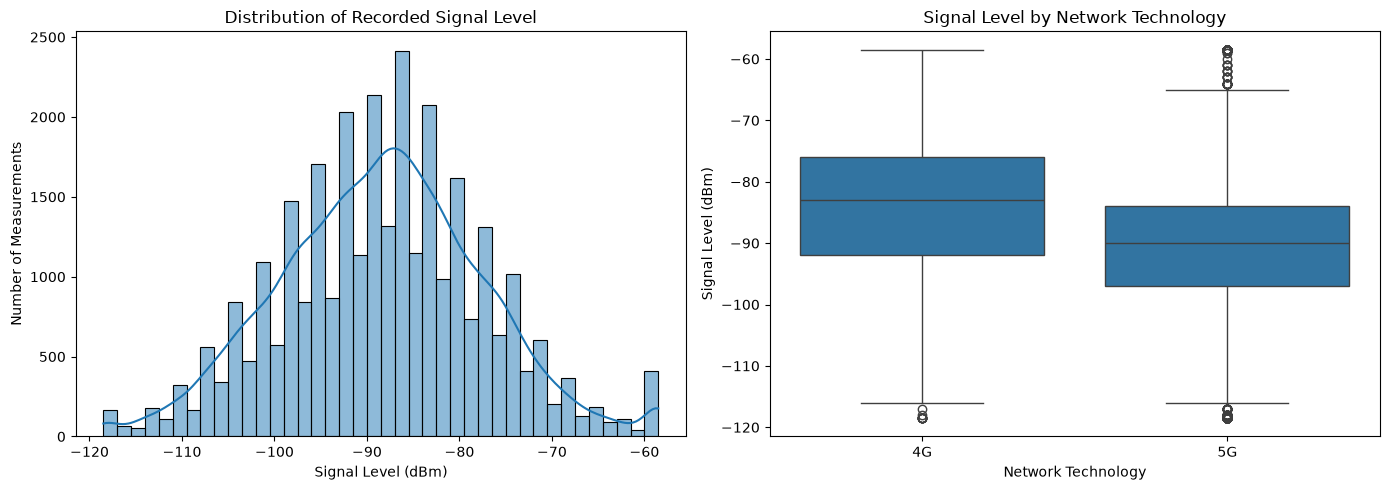

In [5]:
# Step 1X: Target distribution and 4G/5G comparison

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overall signal-level distribution
sns.histplot(
    data=df,
    x="Level",
    bins=40,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Recorded Signal Level")
axes[0].set_xlabel("Signal Level (dBm)")
axes[0].set_ylabel("Number of Measurements")

# Compare 4G and 5G signal levels
sns.boxplot(
    data=df,
    x="NetworkTech",
    y="Level",
    order=["4G", "5G"],
    ax=axes[1]
)
axes[1].set_title("Signal Level by Network Technology")
axes[1].set_xlabel("Network Technology")
axes[1].set_ylabel("Signal Level (dBm)")

plt.tight_layout()
plt.show()

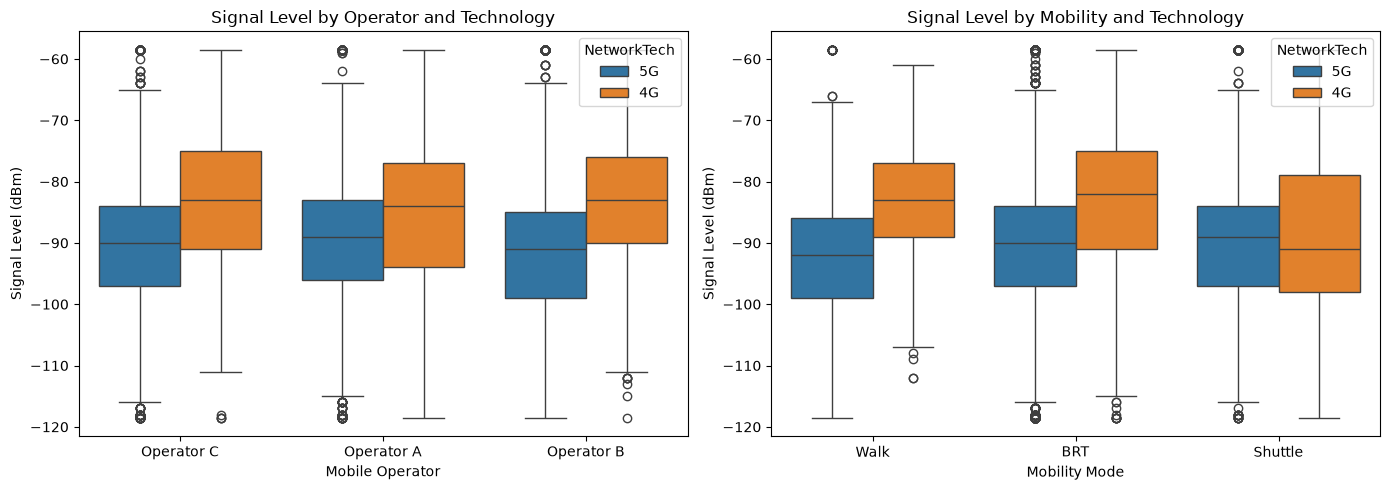

count   mean  median    std
Operatorname NetworkTech                             
Operator A   4G            3984 -85.78   -84.0  11.80
             5G            6558 -89.25   -89.0  10.08
Operator B   4G            2593 -82.98   -83.0  10.06
             5G            7594 -91.70   -91.0  10.64
Operator C   4G            3316 -83.24   -83.0  10.65
             5G            6880 -90.28   -90.0  10.52

In [6]:
# Step 1Y: Signal level by operator and mobility

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="Operatorname",
    y="Level",
    hue="NetworkTech",
    ax=axes[0]
)
axes[0].set_title("Signal Level by Operator and Technology")
axes[0].set_xlabel("Mobile Operator")
axes[0].set_ylabel("Signal Level (dBm)")

sns.boxplot(
    data=df,
    x="Mobility",
    y="Level",
    hue="NetworkTech",
    ax=axes[1]
)
axes[1].set_title("Signal Level by Mobility and Technology")
axes[1].set_xlabel("Mobility Mode")
axes[1].set_ylabel("Signal Level (dBm)")

plt.tight_layout()
plt.show()

# Numerical summary
summary = (
    df.groupby(["Operatorname", "NetworkTech"])["Level"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(summary)

Top 15 numerical correlations with Level:


,Correlation
LTERSSI,0.928044
SecondCell_RSRP,0.666132
NRxLev1,0.642693
SNR,0.351718
CQI,0.227104
SecondCell_SNR,0.205139
NQual1,0.149705
SecondCell_CELLID,0.135028
SecondCell_PSC,0.128835
Altitude,0.128770


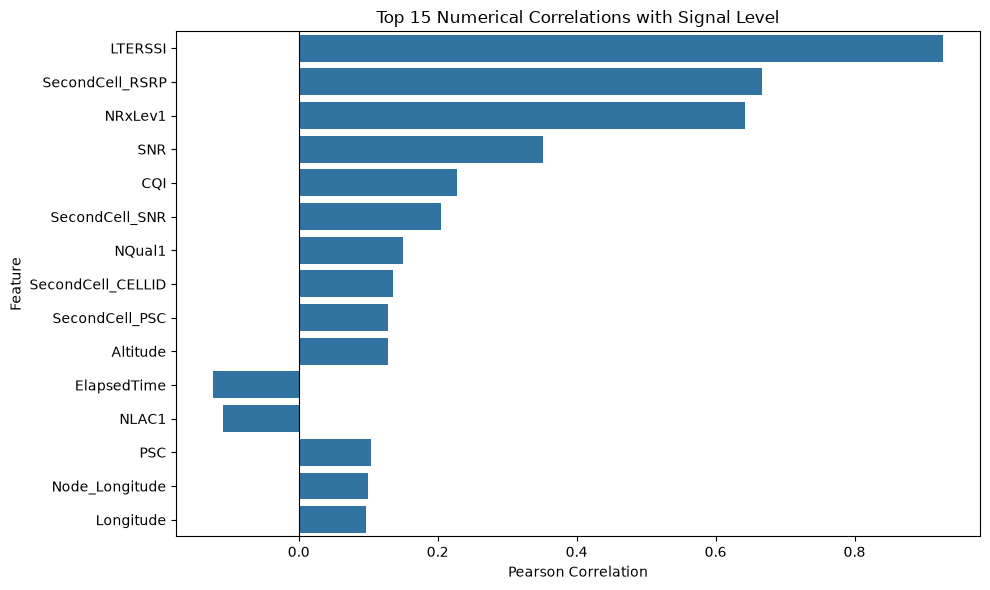

In [7]:
# Step 1Z: Numerical feature correlations with signal level

numeric_df = df.select_dtypes(include="number")

correlations = (
    numeric_df.corr(numeric_only=True)["Level"]
    .drop("Level")
    .dropna()
    .sort_values(key=abs, ascending=False)
)

print("Top 15 numerical correlations with Level:")
display(correlations.head(15).to_frame("Correlation"))

plt.figure(figsize=(10, 6))

sns.barplot(
    x=correlations.head(15).values,
    y=correlations.head(15).index
)

plt.title("Top 15 Numerical Correlations with Signal Level")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

In [8]:
# Step 2A: Examine candidate model features

features = [
    "Latitude",
    "Longitude",
    "Speed",
    "Operatorname",
    "NetworkTech",
    "Mobility",
    "Altitude",
    "ARFCN",
    "BANDWIDTH"
]

X = df[features].copy()
y = df["Level"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values:")
display(X.isna().sum().to_frame("Missing Count"))

print("\nCategorical feature distributions:")
for column in ["Operatorname", "NetworkTech", "Mobility"]:
    print(f"\n{column}:")
    display(X[column].value_counts())

print("\nNumerical feature statistics:")
display(X.select_dtypes(include="number").describe().T)

Feature matrix shape: (30925, 9)
Target shape: (30925,)

Missing values:


,Missing Count
Latitude,0
Longitude,0
Speed,0
Operatorname,0
NetworkTech,0
Mobility,0
Altitude,0
ARFCN,0
BANDWIDTH,1162



Categorical feature distributions:

Operatorname:


Operatorname
Operator A    10542
Operator C    10196
Operator B    10187
Name: count, dtype: int64


NetworkTech:


NetworkTech
5G    21032
4G     9893
Name: count, dtype: int64


Mobility:


Mobility
BRT        17211
Shuttle     7885
Walk        5829
Name: count, dtype: int64


Numerical feature statistics:


,count,mean,std,min,25%,50%,75%,max
Latitude,30925.0,3.067838,0.005420,3.056521,3.065236,3.067716,3.071047,3.079762
Longitude,30925.0,101.605300,0.005197,101.591714,101.602289,101.606267,101.609945,101.613326
Speed,30925.0,16.066257,14.649142,0.000000,3.000000,14.000000,29.000000,68.000000
Altitude,30925.0,27.647809,18.664950,-11.500000,20.000000,27.000000,41.000000,72.500000
ARFCN,30925.0,9310.000000,0.000000,9310.000000,9310.000000,9310.000000,9310.000000,9310.000000
BANDWIDTH,29763.0,20.000000,0.000000,20.000000,20.000000,20.000000,20.000000,20.000000


In [9]:
# Step 2B: Session-aware train/validation/test split

from sklearn.model_selection import GroupShuffleSplit

features = [
    "Latitude",
    "Longitude",
    "Speed",
    "Operatorname",
    "NetworkTech",
    "Mobility",
    "Altitude"
]

X = df[features].copy()
y = df["Level"].copy()
groups = df["SessionID"]

# First split: 60% training, 40% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.40,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(X, y, groups=groups)
)

# Second split: temporary data into validation and test
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_relative_idx, test_relative_idx = next(
    split2.split(
        X.iloc[temp_idx],
        y.iloc[temp_idx],
        groups=groups.iloc[temp_idx]
    )
)

val_idx = temp_idx[val_relative_idx]
test_idx = temp_idx[test_relative_idx]

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Test records:", len(X_test))

train_sessions = set(groups.iloc[train_idx])
val_sessions = set(groups.iloc[val_idx])
test_sessions = set(groups.iloc[test_idx])

print("\nSession counts:")
print("Train:", len(train_sessions))
print("Validation:", len(val_sessions))
print("Test:", len(test_sessions))

print("\nOverlapping sessions:")
print("Train/Val:", train_sessions & val_sessions)
print("Train/Test:", train_sessions & test_sessions)
print("Val/Test:", val_sessions & test_sessions)

print("\nTechnology distribution:")
for name, indices in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    print(name, df.iloc[indices]["NetworkTech"].value_counts().to_dict())

Training records: 16768
Validation records: 8862
Test records: 5295

Session counts:
Train: 13
Validation: 5
Test: 5

Overlapping sessions:
Train/Val: set()
Train/Test: set()
Val/Test: set()

Technology distribution:
Train {'5G': 11141, '4G': 5627}
Validation {'5G': 6498, '4G': 2364}
Test {'5G': 3393, '4G': 1902}


In [10]:
# Step 2C: Baseline regression model

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Train baseline using training data only
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

# Predict on validation data
y_pred_baseline = baseline.predict(X_val)

# Calculate evaluation metrics
baseline_rmse = np.sqrt(
    mean_squared_error(y_val, y_pred_baseline)
)
baseline_mae = mean_absolute_error(
    y_val, y_pred_baseline
)

print("Baseline Regression Results")
print("---------------------------")
print(f"Training mean Level: {y_train.mean():.2f} dBm")
print(f"Validation RMSE: {baseline_rmse:.4f} dB")
print(f"Validation MAE: {baseline_mae:.4f} dB")

Baseline Regression Results
---------------------------
Training mean Level: -87.97 dBm
Validation RMSE: 11.0004 dB
Validation MAE: 8.5008 dB


In [11]:
# Step 2D: Linear Regression with preprocessing pipeline

from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

categorical_features = [
    "Operatorname",
    "NetworkTech",
    "Mobility"
]

numerical_features = [
    "Latitude",
    "Longitude",
    "Speed",
    "Altitude"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

# Train model
linear_model.fit(X_train, y_train)

# Predict validation dataset
y_pred_linear = linear_model.predict(X_val)

# Evaluate
linear_rmse = np.sqrt(
    mean_squared_error(y_val, y_pred_linear)
)
linear_mae = mean_absolute_error(
    y_val, y_pred_linear
)

print("Linear Regression Results")
print("-------------------------")
print(f"Validation RMSE: {linear_rmse:.4f} dB")
print(f"Validation MAE: {linear_mae:.4f} dB")

print("\nBaseline comparison:")
print(f"Baseline RMSE: {baseline_rmse:.4f} dB")
print(f"Linear RMSE:   {linear_rmse:.4f} dB")
print(f"RMSE improvement: {baseline_rmse - linear_rmse:.4f} dB")

Linear Regression Results
-------------------------
Validation RMSE: 10.2551 dB
Validation MAE: 8.0103 dB

Baseline comparison:
Baseline RMSE: 11.0004 dB
Linear RMSE:   10.2551 dB
RMSE improvement: 0.7453 dB


In [12]:
# Step 2E: Decision Tree Regression

from sklearn.tree import DecisionTreeRegressor

tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(
            max_depth=6,
            min_samples_leaf=20,
            random_state=42
        ))
    ]
)

# Train the model
tree_model.fit(X_train, y_train)

# Predict validation data
y_pred_tree = tree_model.predict(X_val)

# Evaluate model
tree_rmse = np.sqrt(
    mean_squared_error(y_val, y_pred_tree)
)
tree_mae = mean_absolute_error(
    y_val, y_pred_tree
)

print("Decision Tree Regression Results")
print("--------------------------------")
print(f"Validation RMSE: {tree_rmse:.4f} dB")
print(f"Validation MAE: {tree_mae:.4f} dB")

print("\nModel Comparison:")
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Decision Tree"
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        tree_rmse
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        tree_mae
    ]
})

display(results.sort_values("RMSE"))

Decision Tree Regression Results
--------------------------------
Validation RMSE: 8.8686 dB
Validation MAE: 6.7149 dB

Model Comparison:


,Model,RMSE,MAE
2,Decision Tree,8.868566,6.714859
1,Linear Regression,10.255136,8.010279
0,Baseline,11.000448,8.500774


In [13]:
# Step 2F: Random Forest Regression

from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=12,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train model
rf_model.fit(X_train, y_train)

# Predict validation data
y_pred_rf = rf_model.predict(X_val)

# Evaluate
rf_rmse = np.sqrt(
    mean_squared_error(y_val, y_pred_rf)
)
rf_mae = mean_absolute_error(
    y_val, y_pred_rf
)

print("Random Forest Regression Results")
print("--------------------------------")
print(f"Validation RMSE: {rf_rmse:.4f} dB")
print(f"Validation MAE: {rf_mae:.4f} dB")

# Updated model comparison
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        tree_rmse,
        rf_rmse
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        tree_mae,
        rf_mae
    ]
})

display(results.sort_values("RMSE"))

Random Forest Regression Results
--------------------------------
Validation RMSE: 8.6832 dB
Validation MAE: 6.3381 dB


,Model,RMSE,MAE
3,Random Forest,8.683205,6.338052
2,Decision Tree,8.868566,6.714859
1,Linear Regression,10.255136,8.010279
0,Baseline,11.000448,8.500774


In [14]:
# Step 2G: XGBoost Regression

from xgboost import XGBRegressor

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", XGBRegressor(
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train model
xgb_model.fit(X_train, y_train)

# Predict validation data
y_pred_xgb = xgb_model.predict(X_val)

# Evaluate
xgb_rmse = np.sqrt(
    mean_squared_error(y_val, y_pred_xgb)
)
xgb_mae = mean_absolute_error(
    y_val, y_pred_xgb
)

print("XGBoost Regression Results")
print("--------------------------")
print(f"Validation RMSE: {xgb_rmse:.4f} dB")
print(f"Validation MAE: {xgb_mae:.4f} dB")

# Compare all models
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        tree_rmse,
        rf_rmse,
        xgb_rmse
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        tree_mae,
        rf_mae,
        xgb_mae
    ]
})

display(results.sort_values("RMSE").reset_index(drop=True))

XGBoost Regression Results
--------------------------
Validation RMSE: 8.8540 dB
Validation MAE: 6.3950 dB


,Model,RMSE,MAE
0,Random Forest,8.683205,6.338052
1,XGBoost,8.854016,6.395011
2,Decision Tree,8.868566,6.714859
3,Linear Regression,10.255136,8.010279
4,Baseline,11.000448,8.500774


In [15]:
# Step 2H: Random Forest hyperparameter tuning

from itertools import product
from sklearn.ensemble import RandomForestRegressor

# Preprocess training and validation data once
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

# Hyperparameter combinations
depths = [8, 12, 16, 20]
leaf_sizes = [2, 5, 10]
estimators = [100, 200]

tuning_results = []

for depth, leaf, n_trees in product(
    depths, leaf_sizes, estimators
):
    model = RandomForestRegressor(
        n_estimators=n_trees,
        max_depth=depth,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_val_processed)

    rmse = np.sqrt(
        mean_squared_error(y_val, predictions)
    )
    mae = mean_absolute_error(
        y_val, predictions
    )

    tuning_results.append({
        "max_depth": depth,
        "min_samples_leaf": leaf,
        "n_estimators": n_trees,
        "RMSE": rmse,
        "MAE": mae
    })

rf_tuning_df = pd.DataFrame(tuning_results)
rf_tuning_df = rf_tuning_df.sort_values("RMSE")

print("Top 10 Random Forest configurations:")
display(rf_tuning_df.head(10))

print("\nBest Random Forest parameters:")
print(rf_tuning_df.iloc[0].to_dict())

print(f"\nOriginal Random Forest RMSE: {rf_rmse:.4f}")
print(f"Best tuned RMSE: {rf_tuning_df.iloc[0]['RMSE']:.4f}")

Top 10 Random Forest configurations:


,max_depth,min_samples_leaf,n_estimators,RMSE,MAE
23,20,10,200,8.448616,6.193266
17,16,10,200,8.467207,6.208967
22,20,10,100,8.478379,6.206904
11,12,10,200,8.485109,6.238506
16,16,10,100,8.488387,6.213552
10,12,10,100,8.531207,6.269254
5,8,10,200,8.657772,6.462870
9,12,5,200,8.660247,6.317606
21,20,5,200,8.661553,6.295380
15,16,5,200,8.666169,6.299836



Best Random Forest parameters:
{'max_depth': 20.0, 'min_samples_leaf': 10.0, 'n_estimators': 200.0, 'RMSE': 8.448616254473015, 'MAE': 6.193265827948608}

Original Random Forest RMSE: 8.6832
Best tuned RMSE: 8.4486


In [16]:
# Step 2I: Train best Random Forest and check overfitting

best_params = rf_tuning_df.iloc[0]

best_rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=int(best_params["n_estimators"]),
            max_depth=int(best_params["max_depth"]),
            min_samples_leaf=int(best_params["min_samples_leaf"]),
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train on training dataset only
best_rf_model.fit(X_train, y_train)

# Predictions
y_train_pred = best_rf_model.predict(X_train)
y_val_pred = best_rf_model.predict(X_val)

# Calculate training and validation errors
train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred)
)
val_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred)
)

train_mae = mean_absolute_error(
    y_train, y_train_pred
)
val_mae = mean_absolute_error(
    y_val, y_val_pred
)

print("Best Random Forest - Overfitting Check")
print("--------------------------------------")
print(f"Training RMSE:   {train_rmse:.4f} dB")
print(f"Validation RMSE: {val_rmse:.4f} dB")
print(f"Training MAE:    {train_mae:.4f} dB")
print(f"Validation MAE:  {val_mae:.4f} dB")
print(f"RMSE Gap:        {val_rmse - train_rmse:.4f} dB")

print("\nBest hyperparameters:")
print(best_rf_model.named_steps["model"].get_params())

Best Random Forest - Overfitting Check
--------------------------------------
Training RMSE:   4.7766 dB
Validation RMSE: 8.4486 dB
Training MAE:    3.0742 dB
Validation MAE:  6.1933 dB
RMSE Gap:        3.6720 dB

Best hyperparameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 20, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 10, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 200, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [17]:
# Step 2J: XGBoost hyperparameter tuning

from itertools import product
from xgboost import XGBRegressor

xgb_tuning_results = []

depths = [3, 5, 7, 9]
learning_rates = [0.03, 0.1]
child_weights = [5, 15]

for depth, lr, child_weight in product(
    depths, learning_rates, child_weights
):
    model = XGBRegressor(
        n_estimators=300,
        max_depth=depth,
        learning_rate=lr,
        min_child_weight=child_weight,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_val_processed)

    rmse = np.sqrt(
        mean_squared_error(y_val, predictions)
    )
    mae = mean_absolute_error(
        y_val, predictions
    )

    xgb_tuning_results.append({
        "max_depth": depth,
        "learning_rate": lr,
        "min_child_weight": child_weight,
        "n_estimators": 300,
        "RMSE": rmse,
        "MAE": mae
    })

xgb_tuning_df = pd.DataFrame(xgb_tuning_results)
xgb_tuning_df = xgb_tuning_df.sort_values("RMSE")

print("Top 10 XGBoost configurations:")
display(xgb_tuning_df.head(10))

print("\nBest XGBoost parameters:")
print(xgb_tuning_df.iloc[0].to_dict())

print(f"\nOriginal XGBoost RMSE: {xgb_rmse:.4f}")
print(f"Best tuned XGBoost RMSE: {xgb_tuning_df.iloc[0]['RMSE']:.4f}")
print(f"Best tuned Random Forest RMSE: {val_rmse:.4f}")

Top 10 XGBoost configurations:


,max_depth,learning_rate,min_child_weight,n_estimators,RMSE,MAE
8,7,0.03,5,300,8.333515,6.024551
9,7,0.03,15,300,8.347272,6.121744
5,5,0.03,15,300,8.361439,6.191097
13,9,0.03,15,300,8.366055,6.108314
4,5,0.03,5,300,8.385816,6.150216
3,3,0.10,15,300,8.471886,6.295663
7,5,0.10,15,300,8.520126,6.189298
12,9,0.03,5,300,8.536993,6.186750
1,3,0.03,15,300,8.586135,6.468676
0,3,0.03,5,300,8.601769,6.480549



Best XGBoost parameters:
{'max_depth': 7.0, 'learning_rate': 0.03, 'min_child_weight': 5.0, 'n_estimators': 300.0, 'RMSE': 8.333515257624805, 'MAE': 6.0245507708846295}

Original XGBoost RMSE: 8.8540
Best tuned XGBoost RMSE: 8.3335
Best tuned Random Forest RMSE: 8.4486


In [18]:
# Step 2K: Train best XGBoost and check overfitting

best_xgb_params = xgb_tuning_df.iloc[0]

best_xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", XGBRegressor(
            n_estimators=int(best_xgb_params["n_estimators"]),
            max_depth=int(best_xgb_params["max_depth"]),
            learning_rate=float(best_xgb_params["learning_rate"]),
            min_child_weight=float(best_xgb_params["min_child_weight"]),
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Fit on training data only
best_xgb_model.fit(X_train, y_train)

# Generate predictions
xgb_train_pred = best_xgb_model.predict(X_train)
xgb_val_pred = best_xgb_model.predict(X_val)

# Calculate errors
xgb_train_rmse = np.sqrt(
    mean_squared_error(y_train, xgb_train_pred)
)
xgb_val_rmse = np.sqrt(
    mean_squared_error(y_val, xgb_val_pred)
)

xgb_train_mae = mean_absolute_error(
    y_train, xgb_train_pred
)
xgb_val_mae = mean_absolute_error(
    y_val, xgb_val_pred
)

print("Best XGBoost - Overfitting Check")
print("--------------------------------")
print(f"Training RMSE:   {xgb_train_rmse:.4f} dB")
print(f"Validation RMSE: {xgb_val_rmse:.4f} dB")
print(f"Training MAE:    {xgb_train_mae:.4f} dB")
print(f"Validation MAE:  {xgb_val_mae:.4f} dB")
print(f"RMSE Gap:        {xgb_val_rmse - xgb_train_rmse:.4f} dB")

print("\nTuned model comparison:")
comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Train RMSE": [train_rmse, xgb_train_rmse],
    "Validation RMSE": [val_rmse, xgb_val_rmse],
    "Generalization Gap": [
        val_rmse - train_rmse,
        xgb_val_rmse - xgb_train_rmse
    ]
})

display(comparison)

Best XGBoost - Overfitting Check
--------------------------------
Training RMSE:   5.0034 dB
Validation RMSE: 8.3335 dB
Training MAE:    3.4443 dB
Validation MAE:  6.0246 dB
RMSE Gap:        3.3302 dB

Tuned model comparison:


,Model,Train RMSE,Validation RMSE,Generalization Gap
0,Random Forest,4.776627,8.448616,3.671989
1,XGBoost,5.003361,8.333515,3.330154


In [19]:
# Step 2L: Final XGBoost model and test evaluation

# Combine training and validation data
X_train_full = pd.concat(
    [X_train, X_val],
    axis=0
)

y_train_full = pd.concat(
    [y_train, y_val],
    axis=0
)

# Recreate final model with selected hyperparameters
final_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", XGBRegressor(
            n_estimators=300,
            max_depth=7,
            learning_rate=0.03,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train using training + validation data
final_model.fit(X_train_full, y_train_full)

# Evaluate on untouched test set
test_predictions = final_model.predict(X_test)

test_rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions)
)

test_mae = mean_absolute_error(
    y_test, test_predictions
)

print("Final XGBoost Test Results")
print("--------------------------")
print(f"Training records: {len(X_train_full)}")
print(f"Test records:     {len(X_test)}")
print(f"Test RMSE:        {test_rmse:.4f} dB")
print(f"Test MAE:         {test_mae:.4f} dB")

print("\nPreviously measured validation performance:")
print(f"Validation RMSE: {xgb_val_rmse:.4f} dB")
print(f"Validation MAE:  {xgb_val_mae:.4f} dB")

Final XGBoost Test Results
--------------------------
Training records: 25630
Test records:     5295
Test RMSE:        9.1644 dB
Test MAE:         6.9597 dB

Previously measured validation performance:
Validation RMSE: 8.3335 dB
Validation MAE:  6.0246 dB


In [20]:
# Step 3A: Save the final trained model

import pickle
from pathlib import Path

# Create models directory
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

model_path = model_dir / "xgboost_signal_model.bin"

# Save the complete preprocessing + prediction pipeline
with open(model_path, "wb") as f:
    pickle.dump(final_model, f)

print("Model saved successfully!")
print(f"Model path: {model_path.resolve()}")
print(f"Model size: {model_path.stat().st_size / 1024:.2f} KB")

# Verify the saved model can be loaded
with open(model_path, "rb") as f:
    loaded_model = pickle.load(f)

# Check prediction consistency
original_predictions = final_model.predict(X_test.head(5))
loaded_predictions = loaded_model.predict(X_test.head(5))

print("\nPrediction consistency check:")
print(
    "Predictions match:",
    np.allclose(original_predictions, loaded_predictions)
)

Model saved successfully!
Model path: C:\Users\roban\ml-zoomcamp-2026-midterm\models\xgboost_signal_model.bin
Model size: 2124.04 KB

Prediction consistency check:
Predictions match: True


In [1]:
import sys

print("Kernel connection successful!")
print("Python:", sys.executable)

Kernel connection successful!
Python: C:\Users\roban\ml-zoomcamp-2026-midterm\.venv\Scripts\python.exe


In [ ]:
S